# Figure 9 -- the LW26 Figure 1, with what each survey measures (`lw25_fig1_with_unlocalized_counts_contours_mixedmargins`)

Companion mass against semi-major axis for the `epochalypse` one-companion high-SNR population,
the Lammers & Winn (2026) DR4 forecast, and the confirmed Doppler and transit planets. The
`epochalypse` companions are split by their periodogram classification (period localized / not
localized) and drawn as 99\% contours; the LW26 planets are split by whether their MCMC fit
characterizes the orbit ($P_{84}/P_{16} < 1.2$, $M_{84}/M_{16} < 1.2$, best-fit mass
$< 13\,M_{\rm J}$). LW26 fit orbits only for $P_{\rm orb} < 7$ yr, so their *detected* count is a
floor -- the figure labels it with that limit. The margins are fractions across the top (where the populations are *offset*
in separation) and counts up the side (where they differ in *size*). The dashed vertical is the
separation whose period equals the DR4 baseline.

Inputs: `catalog/periodograms/characterization_1_companion_high_snr.parquet`, LW26's released
fits and mock catalog, and the exoplanet archive export their notebook used
(`analysis/data/LW25_GaiaForecasts/`).

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

import paperfig as pf          # paths, style, loaders and the shared figure machinery

pf.setup_style()               # Computer Modern, usetex -- the paper's typography
print("catalog :", pf.CATALOG)
print("paper figures         :", pf.PAPER_FIG_DIR)
print("supplementary figures :", pf.SUPP_FIG_DIR)

catalog : /Users/daniel/Desktop/epochalypse_catalog/catalog
paper figures         : /Users/daniel/Desktop/epochalypse_catalog/analysis/paper_figures
supplementary figures : /Users/daniel/Desktop/epochalypse_catalog/analysis/supplementary_figures


## 1. The LW26 release, and their cuts

Applying their three documented cuts to the master file must reproduce their published catalog
row for row; then the file is split at their 20\% characterization criteria into *forecasted
characterized* and *forecasted detected*, with a mutually exclusive account of why each system
fails to be characterized.

In [2]:
YR = pf.YR
LW = pf.EXTERNAL / "LW25_GaiaForecasts"
master = pd.read_csv(LW / "DR4_master_orbital_fits.csv")
catalog = pd.read_csv(LW / "DR4_mock_exoplanet_catalog.csv")

CHI2 = "\\Delta \\chi^2"
P_TRUE, P_FIT = "True period [days]", "Best-fit period [days]"
P16, P50, P84 = ("MCMC period 16th [days]", "MCMC period 50th [days]", "MCMC period 84th [days]")
M_TRUE, M_FIT = "True planet mass [M_J]", "Best-fit planet mass [M_J]"
M16, M84 = "MCMC planet mass 16th [M_J]", "MCMC planet mass 84th [M_J]"
MSTAR = "Stellar mass [M_\\odot]"

p_ratio = master[P84] / master[P16]
m_ratio = master[M84] / master[M16]
cuts = {"mass < 13 M_J": master[M_FIT] < 13.0, "Delta-chi2 > 50": master[CHI2] > 50.0,
        "P84/P16 < 1.5": p_ratio < 1.5}
in_catalog = np.logical_and.reduce(list(cuts.values()))
for name, mask in cuts.items():
    print(f"  {name:18s} passes {mask.sum():6d} / {len(master)}")
assert in_catalog.sum() == len(catalog), "cut definition does not reproduce the catalog"
print(f"  all three -> {in_catalog.sum()} rows = the published catalog ({len(catalog)})   MATCH")

fc_char = (p_ratio < 1.2) & (m_ratio < 1.2) & (master[M_FIT] < 13.0)
fc_det = ~fc_char
n_char, n_fdet = int(fc_char.sum()), int(fc_det.sum())
miss_P = fc_det & ~(p_ratio < 1.2)
miss_M = fc_det & (p_ratio < 1.2) & ~(m_ratio < 1.2)
miss_13 = fc_det & (p_ratio < 1.2) & (m_ratio < 1.2)
assert int(miss_P.sum() + miss_M.sum() + miss_13.sum()) == n_fdet
localized = (master[CHI2] > 50.0) & (master[M_FIT] < 13.0) & (p_ratio < 1.5)   # their catalog
n_loc = int(localized.sum())

print(f"\n  master file (all Delta-chi2 > 50)             {len(master):7d}")
print(f"    forecasted CHARACTERIZED (both to 20%)     {n_char:7d}")
print(f"    forecasted DETECTED (everything else)      {n_fdet:7d}   = {n_fdet / n_char:.1f}x")
print(f"      period not known to 20%                  {int(miss_P.sum()):7d}")
print(f"      period to 20%, mass not to 20%           {int(miss_M.sum()):7d}")
print(f"      both to 20%, best-fit mass >= 13 M_Jup   {int(miss_13.sum()):7d}")
print(f"  their published catalog (P84/P16 < 1.5)       {n_loc:7d}: "
      f"{int((localized & fc_char).sum()):,} characterized + {int((localized & fc_det).sum()):,} detected")

Pt = master[P_TRUE]
inside = (Pt >= master[P16]) & (Pt <= master[P84])
print(f"\n  posterior coverage (truth inside 16-84; 68% = calibrated): "
      f"characterized {100 * inside[fc_char].mean():.1f}%, detected {100 * inside[fc_det].mean():.1f}%")
LW26_P_MAX_YR = 7.0     # LW26 fit orbits only below this period (Section 4.1 of their paper)
assert Pt.max() / YR <= LW26_P_MAX_YR * (1 + 1e-6), Pt.max() / YR
print(f"  true periods run up to the {LW26_P_MAX_YR:g} yr fitting cap: {100 * np.mean(Pt / YR > 6):.0f}% of the master file sits in the last year")
print(f"  median true period: characterized {np.nanmedian(Pt[fc_char] / YR):.2f} yr, "
      f"detected {np.nanmedian(Pt[fc_det] / YR):.2f} yr")

  mass < 13 M_J      passes  18503 / 29129
  Delta-chi2 > 50    passes  29129 / 29129
  P84/P16 < 1.5      passes  11698 / 29129
  all three -> 7545 rows = the published catalog (7545)   MATCH

  master file (all Delta-chi2 > 50)               29129
    forecasted CHARACTERIZED (both to 20%)        1938
    forecasted DETECTED (everything else)        27191   = 14.0x
      period not known to 20%                    18778
      period to 20%, mass not to 20%              8244
      both to 20%, best-fit mass >= 13 M_Jup       169
  their published catalog (P84/P16 < 1.5)          7545: 1,938 characterized + 5,607 detected

  posterior coverage (truth inside 16-84; 68% = calibrated): characterized 67.5%, detected 35.7%
  true periods run up to the 7 yr fitting cap: 16% of the master file sits in the last year
  median true period: characterized 3.36 yr, detected 4.51 yr


## 2. The `epochalypse` population

The one-companion high-SNR table, with the calibrated flags re-applied from `calibration.json`.
Their $\Delta\chi^2 > 50$ and our `top_power` are the same statistic, so the detection thresholds
can be compared directly: ours lands much higher because the peak is maximized over 15,777 trial
periods (the look-elsewhere effect).

In [3]:
POP_HIGH_SNR = "1_companion_high_snr"
CAL = pf.calibration()
thr_orbit, thr_accel = CAL["thr_orbit"], CAL["thr_accel"]
chars = {POP_HIGH_SNR: pf.load_chars(POP_HIGH_SNR, columns=["gaia_source_id", "klass", "top_power",
                                                           "best_period", "accel_delta_chi2"])}
DET = "detected_cal"

print(f"\n  LW26 detection threshold      Delta-chi2 > 50")
print(f"  epochalypse (null-calibrated) Delta-chi2 > {thr_orbit:.0f}   = {thr_orbit / 50:.1f}x stricter")
print(f"    (measured on all {CAL['n_null_systems']:,} companion-free systems, realized null rate {CAL['realized_fp']:.2%})")
print(f"  LW26 precision cut  P84/P16 < 1.5  ->  d(ln P) < {np.log(1.5):.3f}")
print(f"  epochalypse width threshold        ->  d(ln P) < 0.05   ({np.log(1.5) / 0.05:.0f}x looser on their side)")
d = chars[POP_HIGH_SNR]
for thr, lab in [(50.0, "at LW26's threshold"), (thr_orbit, "at ours")]:
    print(f"  our high-SNR population detected {lab:20s}: {100 * np.mean(d['top_power'] > thr):5.1f}%  "
          f"({int((d['top_power'] > thr).sum()):,} of {len(d):,})")

  1_companion_high_snr     436,883 systems   characterization_1_companion_high_snr.parquet   (SNR_tot >= 5 view)

  LW26 detection threshold      Delta-chi2 > 50
  epochalypse (null-calibrated) Delta-chi2 > 88   = 1.8x stricter
    (measured on all 5,040,328 companion-free systems, realized null rate 0.89%)
  LW26 precision cut  P84/P16 < 1.5  ->  d(ln P) < 0.405
  epochalypse width threshold        ->  d(ln P) < 0.05   (8x looser on their side)
  our high-SNR population detected at LW26's threshold :  61.0%  (266,648 of 436,883)
  our high-SNR population detected at ours             :  46.7%  (204,054 of 436,883)


## 3. The known planets, as LW26 drew them

Their Figure 1 notebook's averaging: per planet, an inverse-variance weighted mean over every
archive row for that planet, then the 20\% cuts. Their code does not drop planets whose stellar
mass is missing -- those get a NaN semi-major axis, are not rendered, but *are* counted -- and
that behaviour is kept so the counts match their notebook output (610 Doppler, 623 transit).

In [4]:
archive = pd.read_csv(LW / "data" / "exoplanet_archive_confirmed_07_2025.csv", skiprows=96)
_arr = np.array(archive)
_names, _methods = _arr[:, 0], _arr[:, 5]


def _vals(ind):
    return _arr[:, ind].astype(float), np.column_stack([_arr[:, ind + 1], _arr[:, ind + 2]]).astype(float)


def _inv_var_mean(vals, uncs):
    mu = 0.5 * (uncs[:, 0] - uncs[:, 1])
    m = ~(np.isnan(mu) | np.isnan(vals) | (mu == 0.0))
    if m.sum() and mu[m].sum() != 0:
        w = 1.0 / mu[m] ** 2
        return (vals[m] * w).sum() / w.sum(), 1.0 / np.sqrt(w.sum())
    return np.nan, np.nan


def _per_planet(vals, uncs, method):
    seen, mean, unc = [], [], []
    for i in range(len(_names)):
        if _methods[i] == method and _names[i] not in seen:
            seen.append(_names[i])
            idx = np.where(_names == _names[i])[0]
            a, b = (_inv_var_mean(vals[idx], uncs[idx]) if len(idx) > 1
                    else (vals[i], 0.5 * (uncs[i][0] - uncs[i][1])))
            mean.append(a); unc.append(b)
    return np.array(mean, float), np.array(unc, float)


_P, _Pu = _vals(11); _M, _Mu = _vals(31); _S, _Su = _vals(59)   # pl_orbper, pl_bmassj, st_mass


def known_planets(method):
    P, dP = _per_planet(_P, _Pu, method)
    M, dM = _per_planet(_M, _Mu, method)
    S, _u = _per_planet(_S, _Su, method)
    with np.errstate(divide="ignore", invalid="ignore"):
        keep = (M < 13.0) & ((M + dM) / (M - dM) < 1.2) & ((P + dP) / (P - dP) < 1.2)
    a = (P[keep] / YR) ** (2 / 3) * (S[keep] + M[keep] * pf.MJUP) ** (1 / 3)
    return a, M[keep]


a_rv, m_rv = known_planets("Radial Velocity")
a_tr, m_tr = known_planets("Transit")
assert len(a_rv) == 610 and len(a_tr) == 623, (len(a_rv), len(a_tr))


def semi_major(P_days, mp_MJ, Mstar):
    return (P_days / YR) ** (2 / 3) * (Mstar + mp_MJ * pf.MJUP) ** (1 / 3)


# every Gaia layer at TRUE injected values, so the layers are mutually comparable
a_char = semi_major(master[P_TRUE][fc_char], master[M_TRUE][fc_char], master[MSTAR][fc_char])
m_char = master[M_TRUE][fc_char]
a_disc = semi_major(master[P_TRUE][fc_det], master[M_TRUE][fc_det], master[MSTAR][fc_det])
m_disc = master[M_TRUE][fc_det]
print(f"known planets: {len(a_rv)} Doppler, {len(a_tr)} transit (LW26 notebook: 610 / 623 -- MATCH); "
      f"plottable (finite stellar mass): {int(np.isfinite(a_rv).sum())} / {int(np.isfinite(a_tr).sum())}")
print(f"Gaia layers: {len(a_char):,} forecasted characterized, {len(a_disc):,} forecasted detected")

known planets: 610 Doppler, 623 transit (LW26 notebook: 610 / 623 -- MATCH); plottable (finite stellar mass): 605 / 623
Gaia layers: 1,938 forecasted characterized, 27,191 forecasted detected


## 4. The figure

The `epochalypse` layer is the high-SNR population restricted to the companions DR4 responds to --
a significant periodogram peak or acceleration against the null-calibrated thresholds -- split into
*period localized* and *not localized* (the null class is not drawn). Every one of those companions
goes into the margins, so a bar is exactly the systems above or beside it.

In [5]:
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
from scipy.ndimage import gaussian_filter

C_20, C_NF = "#A93434", "#DE7D7D"
XLIM, YLIM = (0.006, 200.0), (0.5e-4, 120.0)   # extended past LW26 Fig 1 to hold the epochalypse span
EP_POP = POP_HIGH_SNR
EP_LABEL = "one-companion high-SNR sub-population"
EP_MARKER, EP_ALPHA = pf.MARKER_SIZE, 0.45
KNOWN_SIZE, KNOWN_ALPHA, LW26_ALPHA = pf.MARKER_SIZE * 0.6, 0.62, 0.5
FS, FS_LEGEND = 1.3, 1.25
FS_MARGIN_LABEL = 19 * FS
MARGIN_LABEL_POS = {"top": (0.18, 0.81), "right": (0.02, 127.0)}
CONTOUR_NOTE_POS = (0.52, 0.90)
BASELINE_YR_DR4, BASELINE_LABEL_DR4, BASELINE_LABEL_Y = pf.BASELINE, r"\textit{Gaia} DR4 baseline", 0.065  # label sits between the legend and the LW26 contours

EP_ORDER = pf.DRAW_ORDER                           # back to front: undet, broad, narrow
EP_SHOW = [k for k in EP_ORDER if k != "undet"]    # ...of which these are drawn
EP_LABELS = pf.SHORT_3


def _split(frame):
    """(a [au], m [M_Jup]) per class, for one frame of the one-companion population."""
    d = frame.dropna(subset=["a_1_au", "Mp_1_msun", "period_1"])
    cls = pf.classes(d, 1, det_col=DET)
    av = d["a_1_au"].to_numpy(float)
    mv = d["Mp_1_msun"].to_numpy(float) / pf.MJUP
    return {k: (av[cls == k], mv[cls == k]) for k in EP_ORDER}


ep = ep_all = _split(chars[EP_POP])
print(f"  epochalypse {EP_LABEL}:  " +
      ",  ".join(f"{EP_LABELS[k]} {len(ep[k][0]):,}" + ("" if k in EP_SHOW else "  [not drawn]")
                 for k in EP_ORDER))


def population_contour(ax, x, y, *, color, label, zorder, q=0.95, bins=64, smooth=1.2,
                       lw=2.4, fill=False, fill_alpha=0.16, halo=False, clip_support=True,
                       fill_zorder=None, xlim=None, ylim=None):
    """The smallest region containing a fraction ``q`` of a population, as one contour.

    Density on a log-log grid, lightly smoothed; the level is the achievable step NEAREST
    ``q`` (an integer histogram only admits certain fractions), found on the full smoothed mass
    before the drawn region is clipped to the occupied cells.
    """
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    xlim = XLIM if xlim is None else xlim
    ylim = YLIM if ylim is None else ylim
    xe = np.linspace(np.log10(xlim[0]), np.log10(xlim[1]), int(bins) + 1)
    ye = np.linspace(np.log10(ylim[0]), np.log10(ylim[1]), int(bins) + 1)
    raw, _, _ = np.histogram2d(np.log10(x[ok]), np.log10(y[ok]), bins=(xe, ye))
    H = gaussian_filter(raw, smooth) if smooth else raw.copy()
    flat = np.sort(H.ravel())[::-1]
    csum = np.cumsum(flat)
    levels = []
    if csum[-1] > 0:
        _last = np.r_[flat[:-1] != flat[1:], True]
        _lv, _fr = flat[_last], csum[_last] / csum[-1]
        _pos = _lv > 0
        for _q in np.atleast_1d(q).astype(float):
            levels.append(float(_lv[_pos][np.argmin(np.abs(_fr[_pos] - _q))]))
    levels = sorted(set(levels))
    if clip_support:
        H = H * (raw > 0)
    if levels:
        xc = 10 ** (0.5 * (xe[1:] + xe[:-1]))
        yc = 10 ** (0.5 * (ye[1:] + ye[:-1]))
        if fill:
            for _lev in levels:
                ax.contourf(xc, yc, H.T, levels=[_lev, H.max() + 1.0], colors=[color], alpha=fill_alpha,
                            zorder=(zorder - 0.25) if fill_zorder is None else fill_zorder)
        cs = ax.contour(xc, yc, H.T, levels=levels, colors=[color], linewidths=lw, zorder=zorder)
        if halo:
            cs.set_path_effects([pe.withStroke(linewidth=lw + 2.5, foreground="white")])
    return Line2D([0], [0], color=color, lw=lw, label=label)


def draw_lw26_fig1(marginal_log=False, normalize=False, contours=False, contour_q=0.95,
                   contour_bins=48, contour_smooth=0., contour_known=False,
                   contour_fill=False, contour_fill_alpha=0.16, contour_points=False,
                   contour_note=None, margins=True, known_size=None, known_alpha=None,
                   baseline_years=None, baseline_label=None,
                   stem="lw25_fig1_with_unlocalized_counts", paper=False):
    """LW26's Figure 1 with a marginal histogram on each margin.

    ``normalize`` may be a bool or a ``(top, right)`` pair: fractions of each population per bin
    rather than counts. ``contours`` replaces the markers of the four populations with one
    ``contour_q`` region each; the known-planet layers stay as markers. ``baseline_years`` draws
    the separation whose period equals that baseline (one line for every star, because the top
    axis is $P_{\rm orb}(M_\star/M_\odot)^{0.5}$).
    """
    CONTOUR_Z = 12.0

    def layer(x, y, color, label, zorder, marker="o", size=None, alpha=0.9, points_only=False):
        handle = None
        if (not contours) or contour_points or points_only:
            handle = ax0.scatter(x, y, c=color, marker=marker, s=pf.MARKER_SIZE if size is None else size,
                                 linewidths=0, alpha=alpha, rasterized=True, zorder=zorder, label=label)
        if contours and not points_only:
            line = population_contour(ax0, x, y, color=color, label=label, zorder=CONTOUR_Z + 0.1 * zorder,
                                      q=contour_q, bins=contour_bins, smooth=contour_smooth,
                                      lw=2.6 * FS_LEGEND, fill=contour_fill, fill_alpha=contour_fill_alpha,
                                      halo=contour_points, fill_zorder=zorder - 0.25)
            handle = handle if contour_points else line
        return handle

    if margins:
        fig = plt.figure(figsize=(15.5, 8.8), dpi=140, facecolor="white")
        gs = GridSpec(2, 2, figure=fig, width_ratios=[4.4, 1], height_ratios=[1, 4.0],
                      hspace=0.045, wspace=0.035, left=0.06, right=0.99, top=0.895, bottom=0.085)
        ax0 = fig.add_subplot(gs[1, 0])
        axt = fig.add_subplot(gs[0, 0], sharex=ax0)
        axr = fig.add_subplot(gs[1, 1], sharey=ax0)
        ax1 = axt.twiny()
    else:
        fig = plt.figure(figsize=(13.0, 7.4), dpi=140, facecolor="white")
        fig.subplots_adjust(left=0.06, right=0.99, top=0.88, bottom=0.10)
        ax0 = fig.add_subplot(111)
        axt = axr = None
        ax1 = ax0.twiny()
    ax0.axhline(13.0, c="k", lw=2.5, ls="--", alpha=0.3, zorder=-10)
    ax0.axhline(80.0, c="k", lw=2.5, ls="--", alpha=0.3, zorder=-10)   # the injection prior's ceiling

    h_ep = {}
    for _z, _k in enumerate(EP_SHOW):
        _x, _y = ep[_k]
        h_ep[_k] = layer(_x, _y, pf.CLASS_COLORS[_k], EP_LABELS[_k], 0.5 + 0.5 * _z, marker="s",
                         size=EP_MARKER, alpha=0.45 if _k == "undet" else EP_ALPHA)
    h_nf = layer(a_disc, m_disc, C_NF, ("\\textit{Gaia} DR4 (Lammers \\& Winn, 2026):\n"
                                       f"forecasted orbit detected ({len(a_disc):,}, $P_{{\\rm orb}} < {LW26_P_MAX_YR:g}$ yr)"), 5, alpha=LW26_ALPHA)
    h_20 = layer(a_char, m_char, C_20, ("\\textit{Gaia} DR4 (Lammers \\& Winn, 2026):\n"
                                        f"forecasted orbit characterized ({len(a_char):,})"), 7, alpha=LW26_ALPHA)
    _ksize = KNOWN_SIZE if known_size is None else known_size
    _kalpha = KNOWN_ALPHA if known_alpha is None else known_alpha
    h_rv = layer(a_rv, m_rv, "#33ACE4", f"Doppler method ({len(a_rv)})", 10, size=_ksize, alpha=_kalpha,
                 points_only=not contour_known)
    h_tr = layer(a_tr, m_tr, "mediumseagreen", f"Transit method ({len(a_tr)})", 9, size=_ksize,
                 alpha=_kalpha, points_only=not contour_known)

    ax0.set(xscale="log", yscale="log", xlim=XLIM, ylim=YLIM)
    ax0.set_ylabel(r"companion mass $m_p$ [$M_{\rm J}$]", fontsize=17 * FS, labelpad=5)
    ax0.set_xlabel(r"semi-major axis $a$ [au]", fontsize=17 * FS, labelpad=5)
    ax0.tick_params(labelsize=13 * FS)
    _masslab = dict(ha="center", va="center", c="k", alpha=0.75, fontsize=15 * FS, zorder=25,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
    ax0.text(0.0096, 6.5, r"$13\,M_{\rm J}$", **_masslab)
    ax0.text(0.0096, 40.0, r"$80\,M_{\rm J}$", **_masslab)

    if baseline_years:
        _a_base = float(baseline_years) ** (2.0 / 3.0)
        for _ax in ((ax0, axt) if margins else (ax0,)):
            _ax.axvline(_a_base, c="k", lw=2.5, ls="--", alpha=0.3, zorder=-10)
        ax0.text(_a_base / 1.22, BASELINE_LABEL_Y,
                 baseline_label if baseline_label is not None
                 else BASELINE_LABEL_DR4 if baseline_years == BASELINE_YR_DR4
                 else rf"{baseline_years:g}\,yr baseline", rotation=90, **{**_masslab, "fontsize": 10.5 * FS})
    ax0.scatter([5.2038, 9.5826], [1.0, 0.299409946], c="grey", s=850, edgecolor="none", zorder=20)
    for xx, yy, lab in [(5.24, 0.94, "J"), (9.68, 0.28, "S")]:
        ax0.text(xx, yy, lab, ha="center", va="center", c="white", fontsize=13 * FS, zorder=35)
    _leg = ax0.legend(handles=[h_rv, h_tr, h_20, h_nf], loc="lower right",
                      markerscale=3.0, scatterpoints=1, fontsize=12.5 * FS_LEGEND, ncol=1, columnspacing=0.7,
                      handletextpad=0.5, borderaxespad=0.3, handlelength=1.4,
                      frameon=True, facecolor="white", framealpha=0.88, edgecolor="none")
    ax0.add_artist(_leg)
    ax0.legend(handles=[h_ep[k] for k in pf.LEGEND_ORDER if k in h_ep], loc="lower left",
               title=(r"\textit{Gaia} DR4 \texttt{epochalypse} catalog" "\n" rf"{EP_LABEL}"),
               title_fontsize=18 * FS_LEGEND, alignment="left",
               markerscale=2.0, scatterpoints=1, fontsize=13 * FS_LEGEND, ncol=1,
               handletextpad=0.5, borderaxespad=0.3, handlelength=1.4,
               frameon=True, facecolor="white", framealpha=0.88, edgecolor="none")

    if contours:
        _qs = np.atleast_1d(contour_q).astype(float)
        _note = (contour_note if contour_note is not None else
                 rf"{100 * _qs[0]:.0f}\% contour of each population" if _qs.size == 1 else
                 ", ".join(f"{100 * _q:.0f}" for _q in _qs) + r"\% contours of each population")
        ax0.text(*CONTOUR_NOTE_POS, _note, transform=ax0.transAxes, ha="center", va="center",
                 fontsize=12.5 * FS_LEGEND, zorder=CONTOUR_Z + 10)

    if margins:
        ABINS = np.logspace(np.log10(XLIM[0]), np.log10(XLIM[1]), 46)
        MBINS = np.logspace(np.log10(YLIM[0]), np.log10(YLIM[1]), 46)
        _series = [(ep_all["broad"][0], ep_all["broad"][1], pf.CLASS_COLORS["broad"], 1.7, "period not localized"),
                   (ep_all["narrow"][0], ep_all["narrow"][1], pf.CLASS_COLORS["narrow"], 1.7, "period localized"),
                   (a_disc, m_disc, C_NF, 1.7, f"LW26 forecasted orbit detected ({len(a_disc):,}, $P_{{\\rm orb}} < {LW26_P_MAX_YR:g}$ yr)"),
                   (a_char, m_char, C_20, 1.7, f"LW26 forecasted orbit characterized ({len(a_char):,})")]
        _norm_a, _norm_m = (tuple(normalize) if isinstance(normalize, (tuple, list))
                            else (normalize, normalize))

        def _wt(v, norm):
            v = np.asarray(v, float)
            n = int(np.isfinite(v).sum())
            return np.full(len(v), 1.0 / max(n, 1)) if norm else None

        for _x, _y, _c, _lw, _lab in _series:
            axt.hist(np.asarray(_x, float), bins=ABINS, histtype="step", lw=_lw, color=_c, label=_lab,
                     weights=_wt(_x, _norm_a))
            axr.hist(np.asarray(_y, float), bins=MBINS, histtype="step", lw=_lw, color=_c,
                     orientation="horizontal", weights=_wt(_y, _norm_m))
        _peak_a = max(np.histogram(np.asarray(_x, float), bins=ABINS, weights=_wt(_x, _norm_a))[0].max()
                      for _x, *_ in _series)
        _peak_m = max(np.histogram(np.asarray(_y, float), bins=MBINS, weights=_wt(_y, _norm_m))[0].max()
                      for _x, _y, *_ in _series)
        for _ax in (axt, axr):
            _ax.tick_params(labelsize=11 * FS)
            _ax.grid(alpha=0.12, which="both" if marginal_log else "major")
        if marginal_log:
            _n_max = max(len(_x) for _x, *_ in _series)
            axt.set_yscale("log"); axt.set_ylim((0.5 / _n_max) if _norm_a else 0.7, 4.0 * _peak_a)
            axr.set_xscale("log"); axr.set_xlim((0.5 / _n_max) if _norm_m else 0.7, 4.0 * _peak_m)
        else:
            axt.set_ylim(0, 1.08 * _peak_a)
            axr.set_xlim(0, 1.08 * _peak_m)
        _clab = lambda norm: "fraction of population" if norm else "systems per bin"
        _lbox = dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85)
        axt.text(*MARGIN_LABEL_POS["top"], _clab(_norm_a), transform=axt.transAxes, ha="left", va="top",
                 fontsize=FS_MARGIN_LABEL, bbox=_lbox)
        axr.text(*MARGIN_LABEL_POS["right"], _clab(_norm_m), transform=axr.get_yaxis_transform(),
                 ha="left", va="bottom", fontsize=FS_MARGIN_LABEL, bbox=_lbox)
        axt.tick_params(labelbottom=False)
        axr.tick_params(labelleft=False)
        axr.axhline(13.0, c="k", lw=2.5, ls="--", alpha=0.3, zorder=-10)
        axr.axhline(80.0, c="k", lw=2.5, ls="--", alpha=0.3, zorder=-10)
        for _ax in (axt, axr, ax1):
            for _side in ("top", "right", "bottom", "left"):
                _ax.spines[_side].set_visible(False)

    ax1.set_xscale("log")
    ax1.set_xlim((XLIM[0] ** 1.5) * YR, (XLIM[1] ** 1.5) * YR)
    ax1.set_xlabel(r"$P_{\rm orb}\,(M_\star/M_\odot)^{0.5}$ [days]", fontsize=17 * FS, labelpad=12)
    ax1.tick_params(labelsize=13 * FS)

    pf.save(fig, stem, dpi=140, paper=paper)
    plt.show()
    return fig

  epochalypse one-companion high-SNR sub-population:  no significant peak or acceleration 190,724  [not drawn],  significant peak or acceleration, period not localized 139,827,  significant peak, period localized 106,332


### Markers, linear-count margins

The count version: every `epochalypse` companion drawn as a marker, and both margins in systems
per bin -- the figure that puts the *sizes* of the four populations on the page.

  wrote analysis/supplementary_figures/lw25_fig1_with_unlocalized_counts.pdf, analysis/supplementary_figures/lw25_fig1_with_unlocalized_counts.png


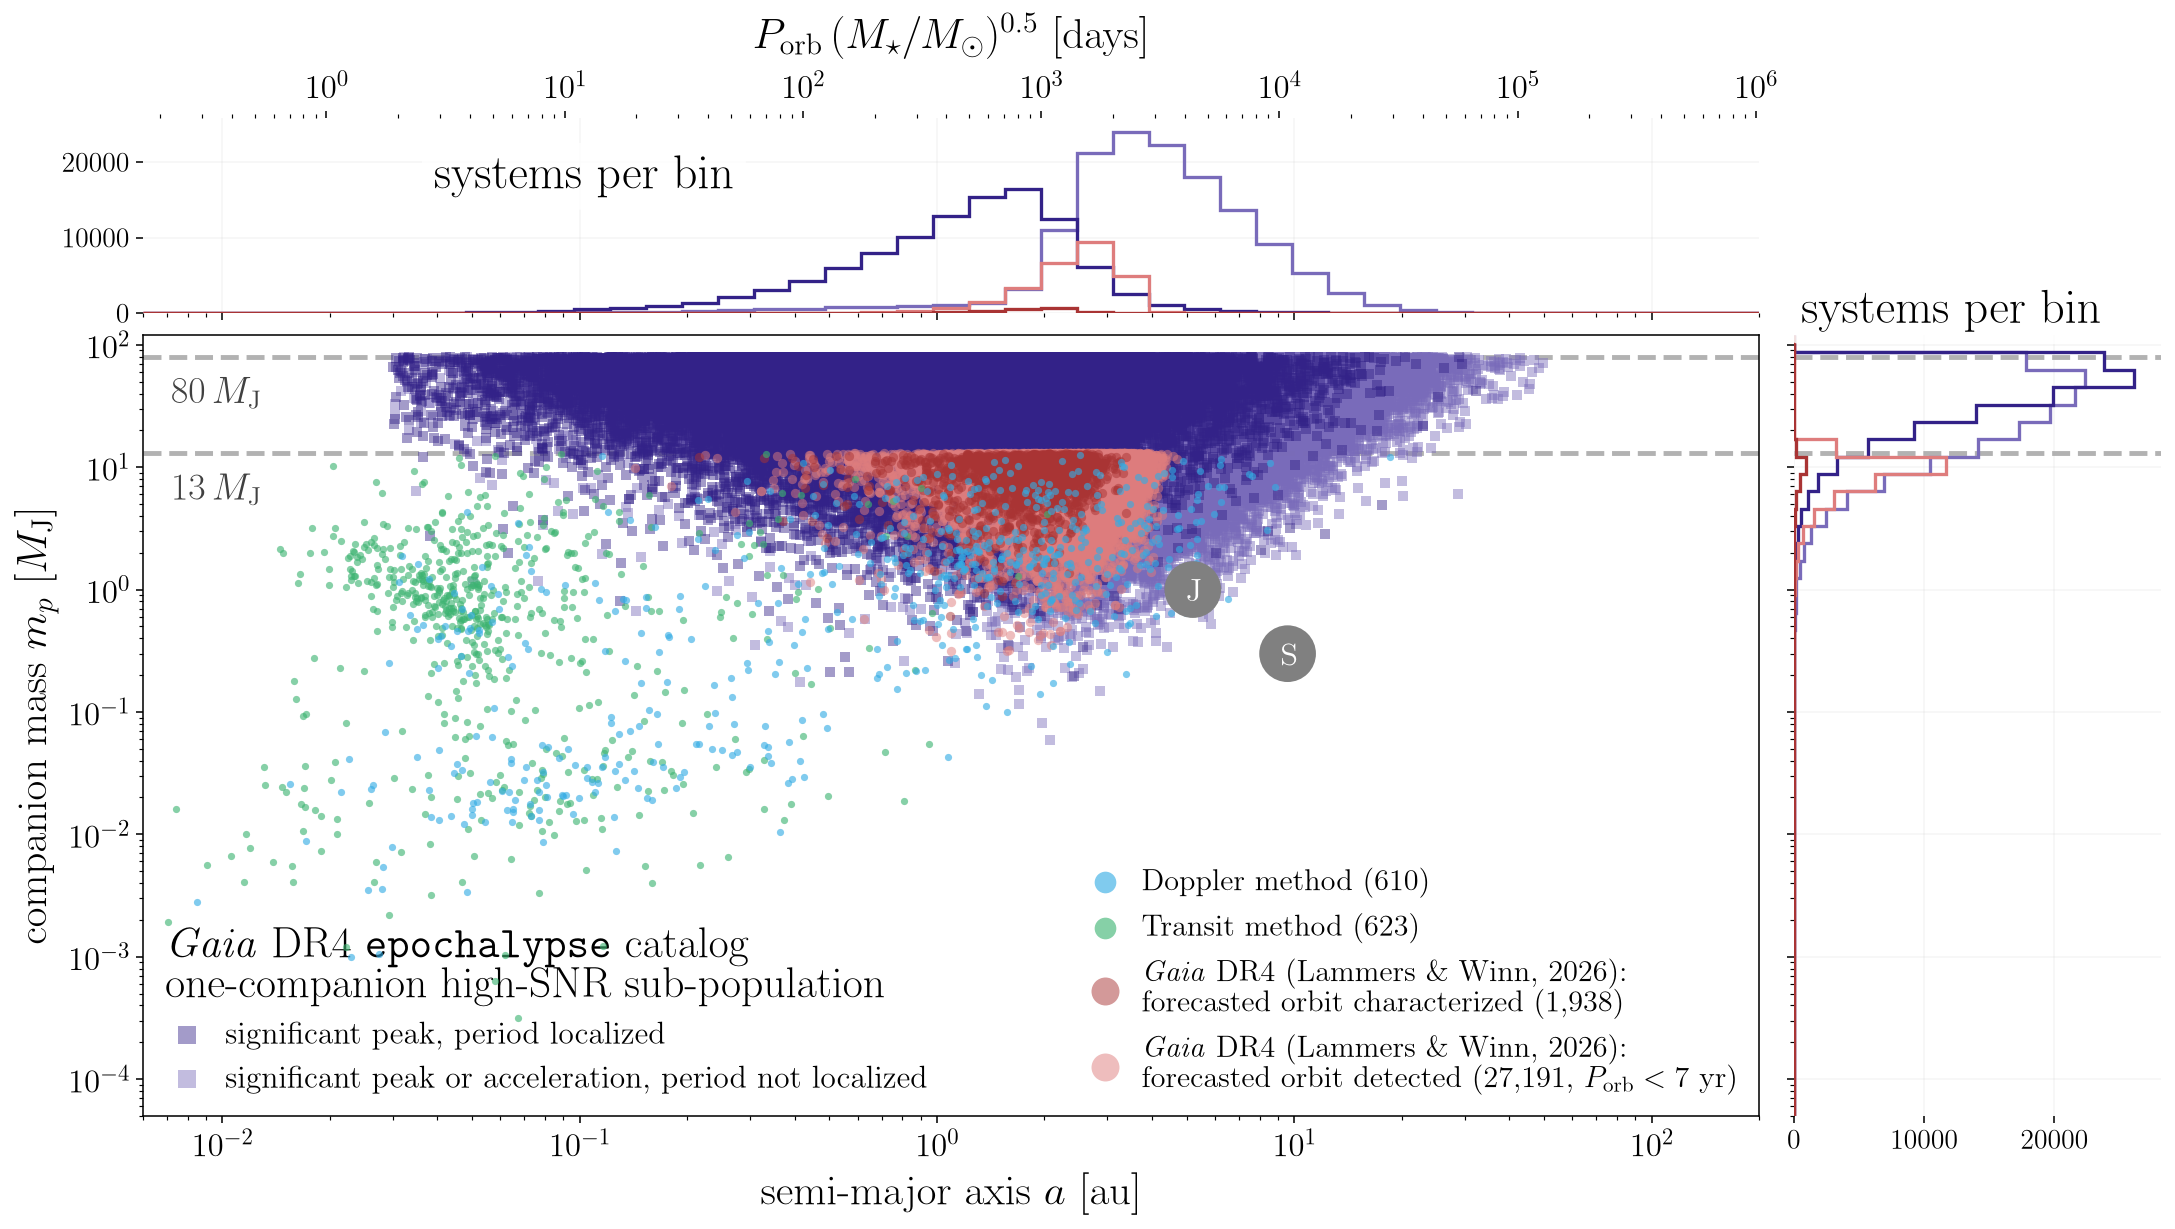

In [6]:
fig = draw_lw26_fig1()

## 5. The paper figure

Contours for *where* (99\% of each population, filled), fractions across the top so the shift in
separation is readable for all four populations, counts up the right so the difference in
population size stays on the page, and the DR4 baseline as a separation.

  wrote analysis/paper_figures/lw25_fig1_with_unlocalized_counts_contours_mixedmargins.pdf, analysis/paper_figures/lw25_fig1_with_unlocalized_counts_contours_mixedmargins.png


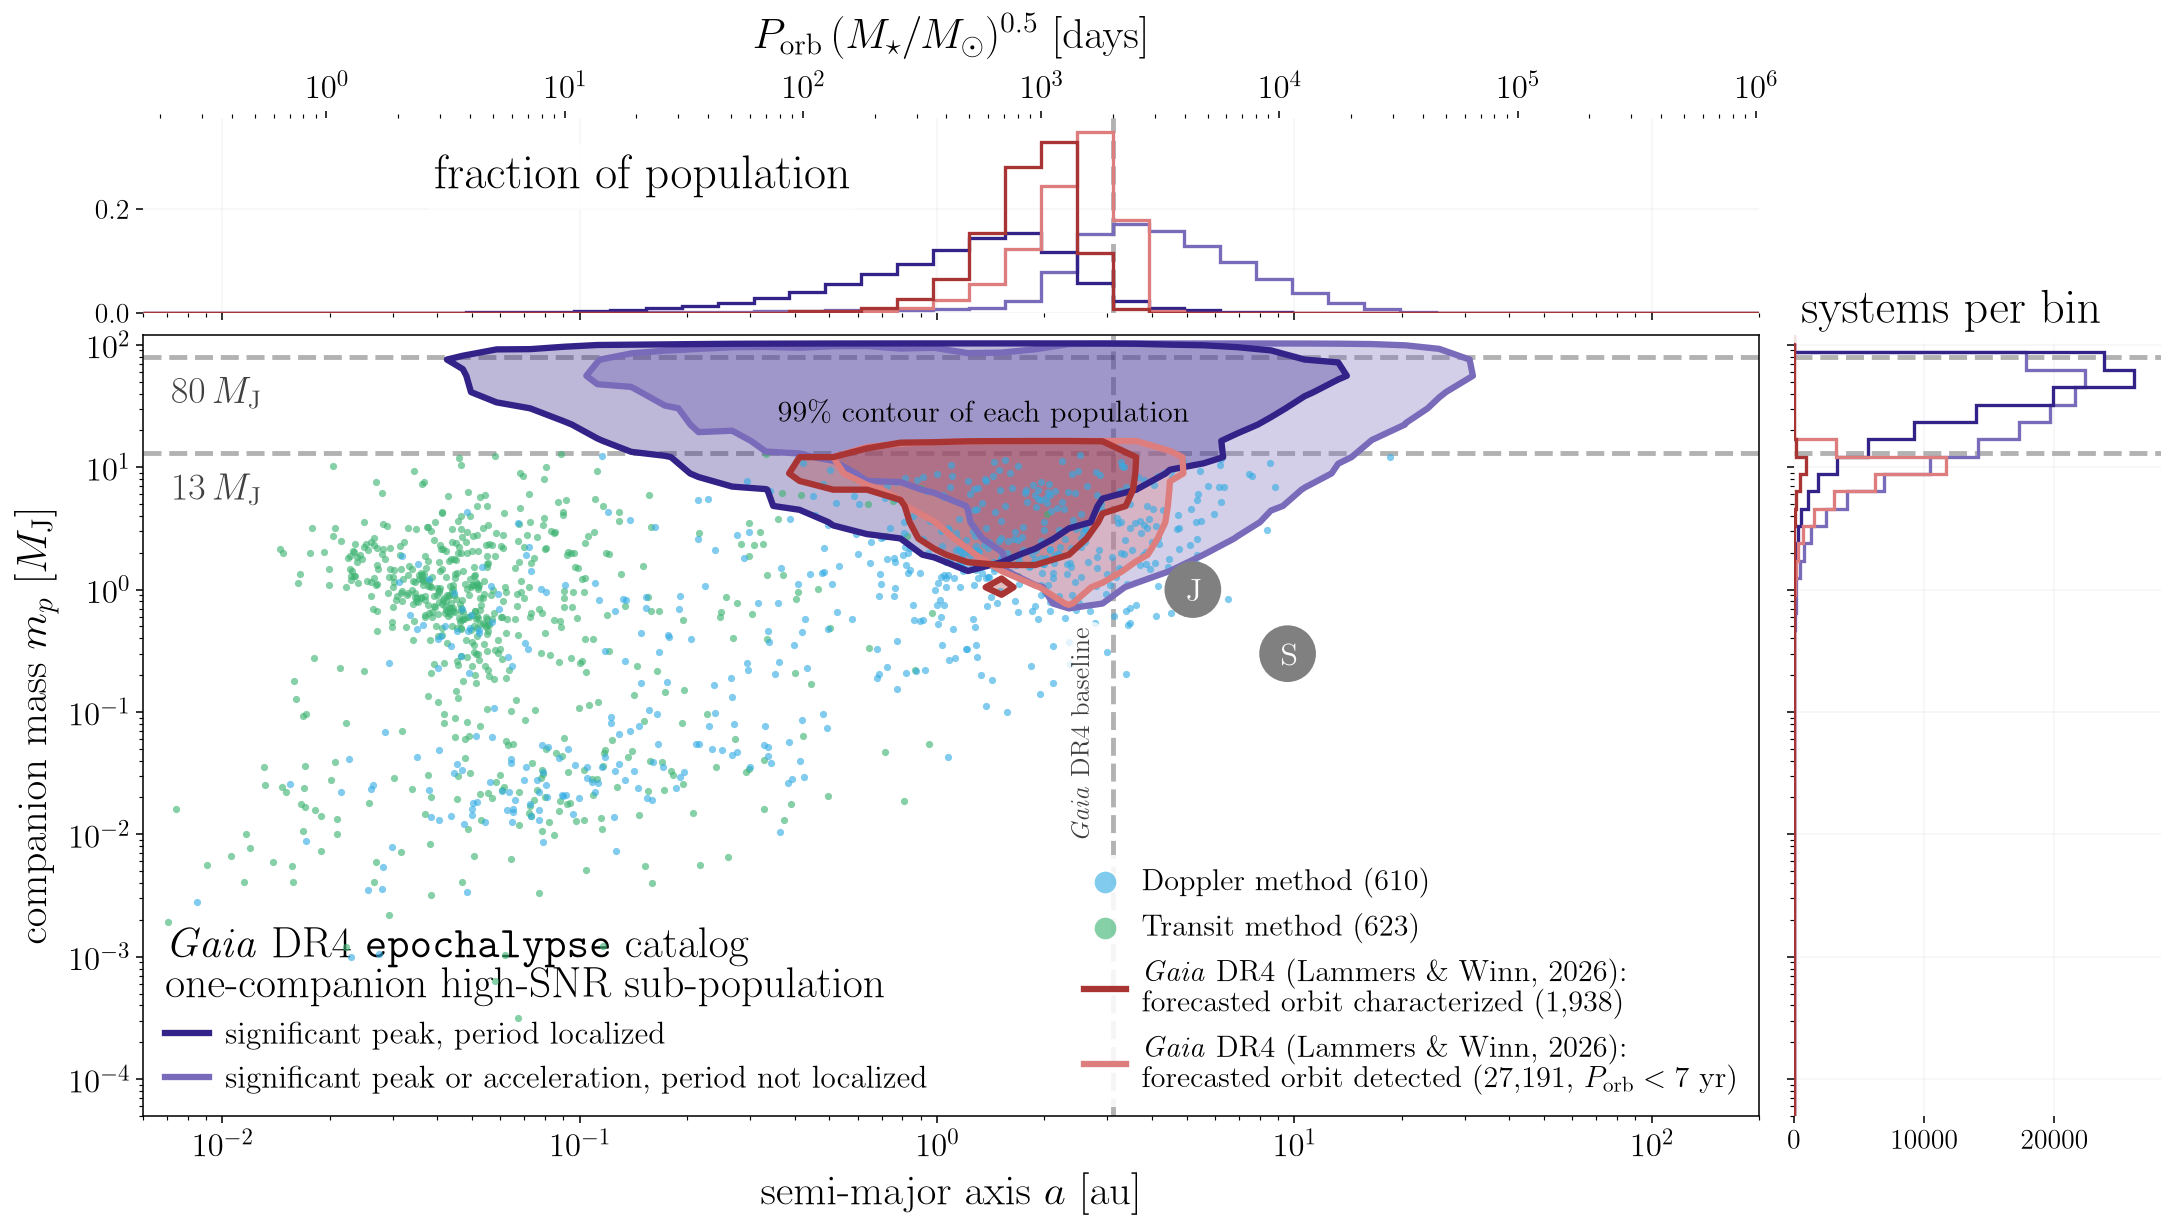

In [7]:
fig = draw_lw26_fig1(contours=True, contour_fill=True, contour_fill_alpha=0.32, contour_q=0.99,
                     margins=True, marginal_log=False, normalize=(True, False),
                     baseline_years=BASELINE_YR_DR4,
                     stem="lw25_fig1_with_unlocalized_counts_contours_mixedmargins", paper=True)